# Evaluación 2 · Clasificación de seis letras ASL con CNN y MLP
**TLY1102 · Técnicas Avanzadas de Machine Learning · Sección 001D**  
**Integrantes:** Nicolás Fernández Vera, Bastian Gutierrez y Victor Gutierrez.  
**Docente:** Jazna Hidalgo.

## 1. Introducción y continuidad
Se conserva la variante de la evaluación 1: **A, C, F, K, O, Y**, etiquetas originales **0, 2, 5, 10, 14, 24**. El objetivo es evaluar si la estructura espacial de una CNN mejora el reconocimiento frente al MLP 784–128–64–6. El uso propuesto es un módulo educativo de reconocimiento de letras estáticas ASL. No reconoce lengua de señas chilena, oraciones ni gestos en movimiento.

La evaluación 1 reportó accuracy **0,8703**, precisión macro **0,8778**, recall macro **0,8698**, F1 macro **0,8694** y **233 errores / 1.797**. Conservamos esa evidencia histórica y reentrenamos el MLP con la CNN en el mismo entorno para medir costos comparables. Las cifras nuevas no sustituyen retrospectivamente las anteriores.

Se utilizan únicamente Input, Conv2D, MaxPooling2D, Flatten y Dense. **Sin Dropout, BatchNormalization ni capas de regularización**, conforme a la rúbrica. Una única configuración CNN prefijada, sin escogerla por resultados del test.

### Ejecución
Descomprimir el proyecto completo, instalar `requirements.txt` y ejecutar todas las celdas en orden. El directorio `data/` contiene los CSV originales. En Colab, subir y descomprimir el ZIP completo en `/content/` antes de abrir el notebook. Se generan modelos, figuras, tablas, índices y huellas de los datos. Los tiempos dependen del hardware.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1") # comparación reproducible en CPU
import json, time, platform, hashlib, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from IPython.display import display, Markdown
SEED, EPOCHS, BATCH_SIZE = 42, 20, 32
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/Evaluacion2_001D')]
ROOT = next((p for p in candidates if (p/'data/sign_mnist_train.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError("Descomprima el proyecto completo y abra el notebook desde notebooks/ o la raíz.")
for d in ['models','images','results']: (ROOT/d).mkdir(exist_ok=True)
LETTERS = ['A','C','F','K','O','Y']
ORIGINAL = [0,2,5,10,14,24]
MAPPING = dict(zip(ORIGINAL, range(6)))
plt.rcParams.update({'figure.dpi':120, 'font.size':11})
def savefig(name):
    plt.tight_layout(); plt.savefig(ROOT/'images'/name, dpi=160, bbox_inches='tight'); plt.show(); plt.close()
environment = {'python':sys.version, 'tensorflow':tf.__version__, 'numpy':np.__version__, 'platform':platform.platform(), 'processor':platform.processor(), 'devices':[str(d) for d in tf.config.list_physical_devices()], 'seed':SEED, 'epochs':EPOCHS, 'batch_size':BATCH_SIZE, 'threads':2, 'oneDNN':os.environ['TF_ENABLE_ONEDNN_OPTS']}
(ROOT/'results/environment.json').write_text(json.dumps(environment,indent=2))
print(json.dumps(environment,indent=2))

{
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "tensorflow": "2.20.0",
  "numpy": "2.3.5",
  "platform": "Linux-6.18.44-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "devices": [
    "PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"
  ],
  "seed": 42,
  "epochs": 20,
  "batch_size": 32,
  "threads": 2,
  "oneDNN": "0"
}


## 2. Preparación de los datos
Se conserva la resolución original 28×28 y el único canal de gris, sin interpolación ni redimensionamiento. El MLP recibe `(N,784)` y la CNN `(N,28,28,1)`. Cambia la representación, no la información. Se divide por 255 **una sola vez**. El test oficial no participa en validación, selección ni ajuste de hiperparámetros.

La división estratificada 80/20 con semilla 42 reproduce la evaluación anterior. Se comprueban nulos, rango, clases, duplicados exactos y separación de particiones. La ausencia de duplicados exactos no demuestra independencia de personas o imágenes aumentadas: no hay identificadores de sujeto en estos CSV.

{
  "train_original": {
    "rows": 27455,
    "columns": 785,
    "nulls": 0,
    "min_pixel": 0,
    "max_pixel": 255
  },
  "test_original": {
    "rows": 7172,
    "columns": 785,
    "nulls": 0,
    "min_pixel": 0,
    "max_pixel": 255
  },
  "duplicates_filtered_train": 0,
  "duplicates_filtered_test": 0,
  "train_test_exact_overlap": 0,
  "train_validation_exact_overlap": 0,
  "sha256": {
    "sign_mnist_train.csv": "4c2897f19fab2b0ae2a7e4fa82e969043315d9f3a1a9cc0948b576bf1189a7e5",
    "sign_mnist_test.csv": "0e9d67bae23e67f40728e0b63bf15ad4bd5175947b8a9fac5dd9f17ce133c47b"
  }
}


Letra,Original,Codificada,Train,Validacion,Test
A,0,0,901,225,331
C,2,1,915,229,310
F,5,2,963,241,247
K,10,3,891,223,331
O,14,4,957,239,246
Y,24,5,894,224,332


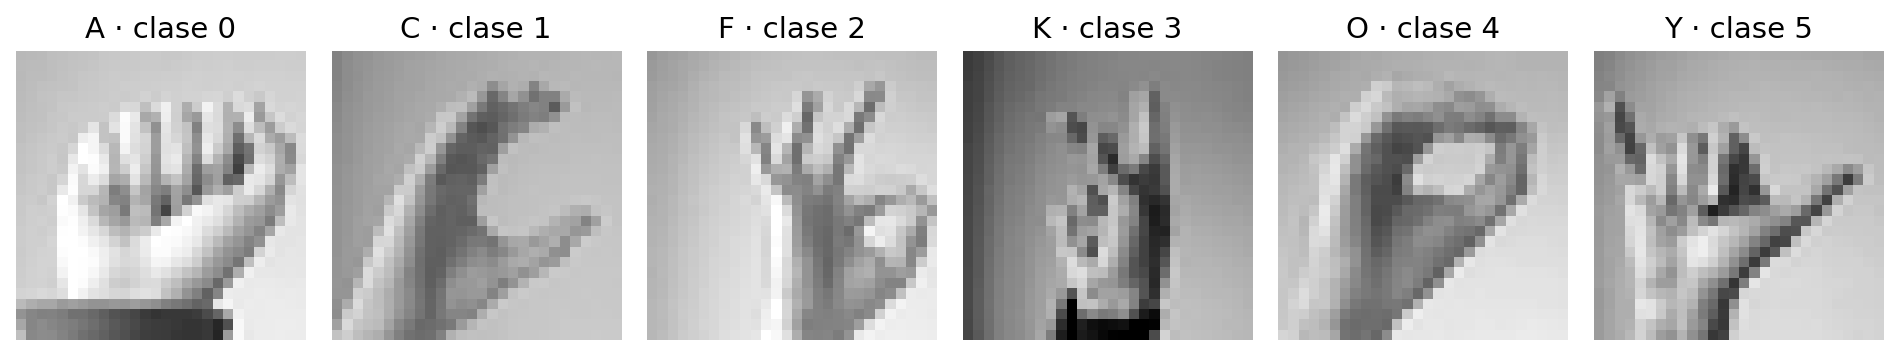

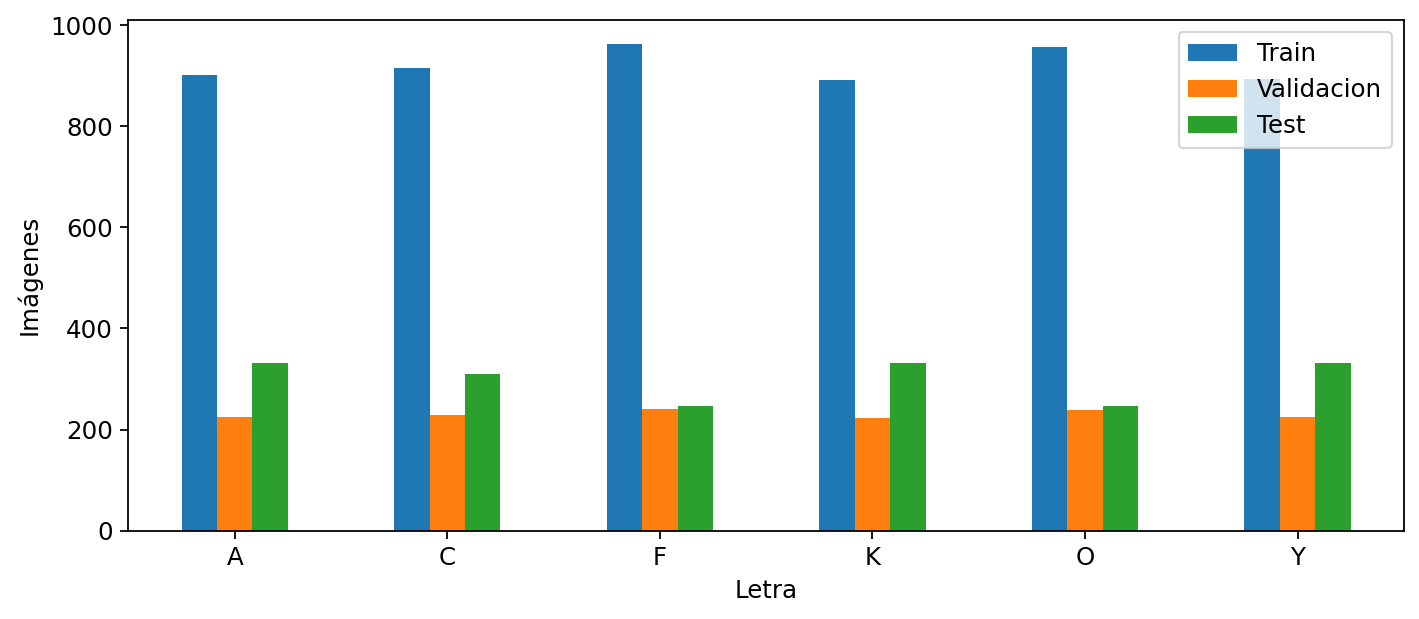

In [2]:
train_raw = pd.read_csv(ROOT/'data/sign_mnist_train.csv')
test_raw = pd.read_csv(ROOT/'data/sign_mnist_test.csv')
quality = {}
for name, frame in [('train_original',train_raw),('test_original',test_raw)]:
    assert frame.shape[1] == 785 and frame.columns[0]=='label'
    assert frame.isna().sum().sum()==0
    assert frame.iloc[:,1:].to_numpy().min()>=0 and frame.iloc[:,1:].to_numpy().max()<=255
    quality[name]={'rows':len(frame),'columns':frame.shape[1],'nulls':int(frame.isna().sum().sum()), 'min_pixel':int(frame.iloc[:,1:].to_numpy().min()),'max_pixel':int(frame.iloc[:,1:].to_numpy().max())}
train = train_raw[train_raw.label.isin(ORIGINAL)].copy()
test = test_raw[test_raw.label.isin(ORIGINAL)].copy()
y = train.label.map(MAPPING).to_numpy(dtype='int64')
yt = test.label.map(MAPPING).to_numpy(dtype='int64')
X = train.iloc[:,1:].to_numpy(dtype='float32')/255.0
Xt = test.iloc[:,1:].to_numpy(dtype='float32')/255.0
itr, iva = train_test_split(np.arange(len(y)),test_size=0.20,random_state=SEED,stratify=y)
Xtr,Xva,ytr,yva=X[itr],X[iva],y[itr],y[iva]
CTr,CVa,CTe=[a.reshape(-1,28,28,1) for a in [Xtr,Xva,Xt]]
assert set(itr).isdisjoint(set(iva)) and len(itr)+len(iva)==len(y)
assert (len(ytr),len(yva),len(yt))==(5521,1381,1797)
assert np.array_equal(CTr.reshape(-1,784),Xtr)
np.savez(ROOT/'results/split_indices.npz',train_filtered=itr,validation_filtered=iva,train_csv_rows=train.index.to_numpy()[itr],validation_csv_rows=train.index.to_numpy()[iva],test_csv_rows=test.index.to_numpy())
def hashes(frame):
    return [hashlib.sha256(row.tobytes()).hexdigest() for row in frame.iloc[:,1:].to_numpy(dtype='uint8')]
ht,hs=hashes(train),hashes(test)
quality['duplicates_filtered_train']=len(ht)-len(set(ht))
quality['duplicates_filtered_test']=len(hs)-len(set(hs))
quality['train_test_exact_overlap']=len(set(ht)&set(hs))
quality['train_validation_exact_overlap']=len(set(np.array(ht)[itr])&set(np.array(ht)[iva]))
quality['sha256']={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in (ROOT/'data').glob('*.csv')}
(ROOT/'results/data_quality.json').write_text(json.dumps(quality,indent=2))
distribution=pd.DataFrame({'Letra':LETTERS,'Original':ORIGINAL,'Codificada':range(6),'Train':np.bincount(ytr,minlength=6),'Validacion':np.bincount(yva,minlength=6),'Test':np.bincount(yt,minlength=6)})
distribution.to_csv(ROOT/'results/class_distribution.csv',index=False)
display(distribution); print(json.dumps(quality,indent=2))
fig,axs=plt.subplots(1,6,figsize=(12,2.8))
for k,ax in enumerate(axs):
    ax.imshow(CTr[np.flatnonzero(ytr==k)[0],:,:,0],cmap='gray',vmin=0,vmax=1);ax.set_title(f'{LETTERS[k]} · clase {k}');ax.axis('off')
savefig('clases.png')
distribution.set_index('Letra')[['Train','Validacion','Test']].plot.bar(figsize=(9,4));plt.ylabel('Imágenes');plt.xticks(rotation=0);savefig('distribucion.png')

## 3. Arquitecturas y decisiones
**MLP:** arquitectura idéntica a E1, Dense 128 ReLU, Dense 64 ReLU y Dense 6 Softmax (109.126 parámetros). Aplanar no borra valores, pero las capas densas no imponen vecindad ni comparten filtros espaciales.

**CNN:** dos bloques Conv2D + MaxPooling2D. Primer bloque: 16 filtros 3×3, stride 1, padding `valid`, ReLU. Segundo: 32 filtros 3×3, misma configuración. Cada pooling usa ventana y stride 2×2. Salida Flatten, Dense 64 ReLU, Dense 6 Softmax.

| Capa | Salida por imagen | Parámetros |
|---|---|---:|
| Entrada | 28×28×1 | 0 |
| Conv2D 16, 3×3 | 26×26×16 | (3×3×1+1)×16 = 160 |
| MaxPooling2D | 13×13×16 | 0 |
| Conv2D 32, 3×3 | 11×11×32 | (3×3×16+1)×32 = 4.640 |
| MaxPooling2D | 5×5×32 | 0 |
| Flatten | 800 | 0 |
| Dense 64 | 64 | (800+1)×64 = 51.264 |
| Dense 6 | 6 | (64+1)×6 = 390 |
| **Total CNN** | **6 probabilidades** | **56.454** |

Filtros 3×3 detectan patrones locales con pocos pesos. El segundo bloque combina respuestas previas. MaxPooling conserva la mayor activación local, reduce dimensiones y aporta cierta tolerancia a desplazamientos, sin asegurar invariancia absoluta. `valid` evita bordes artificiales y mantiene suficiente resolución. ReLU introduce no linealidad y produce cero para entradas negativas. Flatten conecta mapas y clasificador. Softmax normaliza seis puntajes.

**Protocolo común:** Adam (learning rate 0,001), sparse categorical crossentropy (etiquetas enteras), 20 épocas, batch 32, mismas particiones y semilla. Se evalúan los pesos de la última época, igual que en E1. No hay regularización, augmentation, búsqueda por test ni early stopping. Se mantiene un presupuesto de actualizaciones comparable. Una única semilla no estima la variabilidad entre ejecuciones.

In [3]:
L=tf.keras.layers
models={}
histories={}
times={}
def dataset(x,y,training=False):
    ds=tf.data.Dataset.from_tensor_slices((x,y))
    if training: ds=ds.shuffle(len(y),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.batch(BATCH_SIZE)
    opt=tf.data.Options();opt.threading.private_threadpool_size=2;opt.threading.max_intra_op_parallelism=2
    return ds.with_options(opt)
for name,a,b in [('MLP',Xtr,Xva),('CNN',CTr,CVa)]:
    tf.keras.utils.set_random_seed(SEED)
    if name=='MLP':
        model=tf.keras.Sequential([L.Input((784,)),L.Dense(128,activation='relu'),L.Dense(64,activation='relu'),L.Dense(6,activation='softmax')],name='MLP')
    else:
        model=tf.keras.Sequential([L.Input((28,28,1)),L.Conv2D(16,3,activation='relu',name='conv1'),L.MaxPooling2D(2,name='pool1'),L.Conv2D(32,3,activation='relu',name='conv2'),L.MaxPooling2D(2,name='pool2'),L.Flatten(),L.Dense(64,activation='relu',name='dense64'),L.Dense(6,activation='softmax',name='salida')],name='CNN')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    model.summary()
    start=time.perf_counter()
    hist=model.fit(dataset(a,ytr,True),validation_data=dataset(b,yva),epochs=EPOCHS,verbose=2)
    times[name]=time.perf_counter()-start
    models[name]=model;histories[name]=hist.history
    model.save(ROOT/'models'/f'{name.lower()}.keras')
    pd.DataFrame(hist.history,index=np.arange(1,EPOCHS+1)).rename_axis('epoch').to_csv(ROOT/'results'/f'history_{name.lower()}.csv')
assert models['MLP'].count_params()==109126
assert models['CNN'].count_params()==56454

Model: "MLP"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 109,126 (426.27 KB)
 Trainable params: 109,126 (426.27 KB)
 Non-trainable params: 0 (0.00 B)
Epoch 1/20
173/173 - 2s - 12ms/step - accuracy: 0.6564 - loss: 0.9621 - val_accuracy: 0.8081 - val_loss: 0.5615
Epoch 2/20
173/173 - 4s - 21ms/step - accuracy: 0.8949 - loss: 0.3570 - va

/root/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


## 4. Evolución del aprendizaje
Se grafican las 20 épocas completas. Accuracy mide aciertos, mientras loss también penaliza probabilidades incorrectas muy seguras. Una validación cercana al 100% no garantiza generalización a imágenes del test oficial. El tiempo medido incluye `fit` y su validación, no carga de datos ni exportación. Ambos modelos se ejecutan secuencialmente en la misma CPU.

MLP Tiempo (s): 23.848 época de menor val_loss: 20 última val_loss: 0.0015803627902641892
CNN Tiempo (s): 26.997 época de menor val_loss: 20 última val_loss: 5.6962104281410575e-05


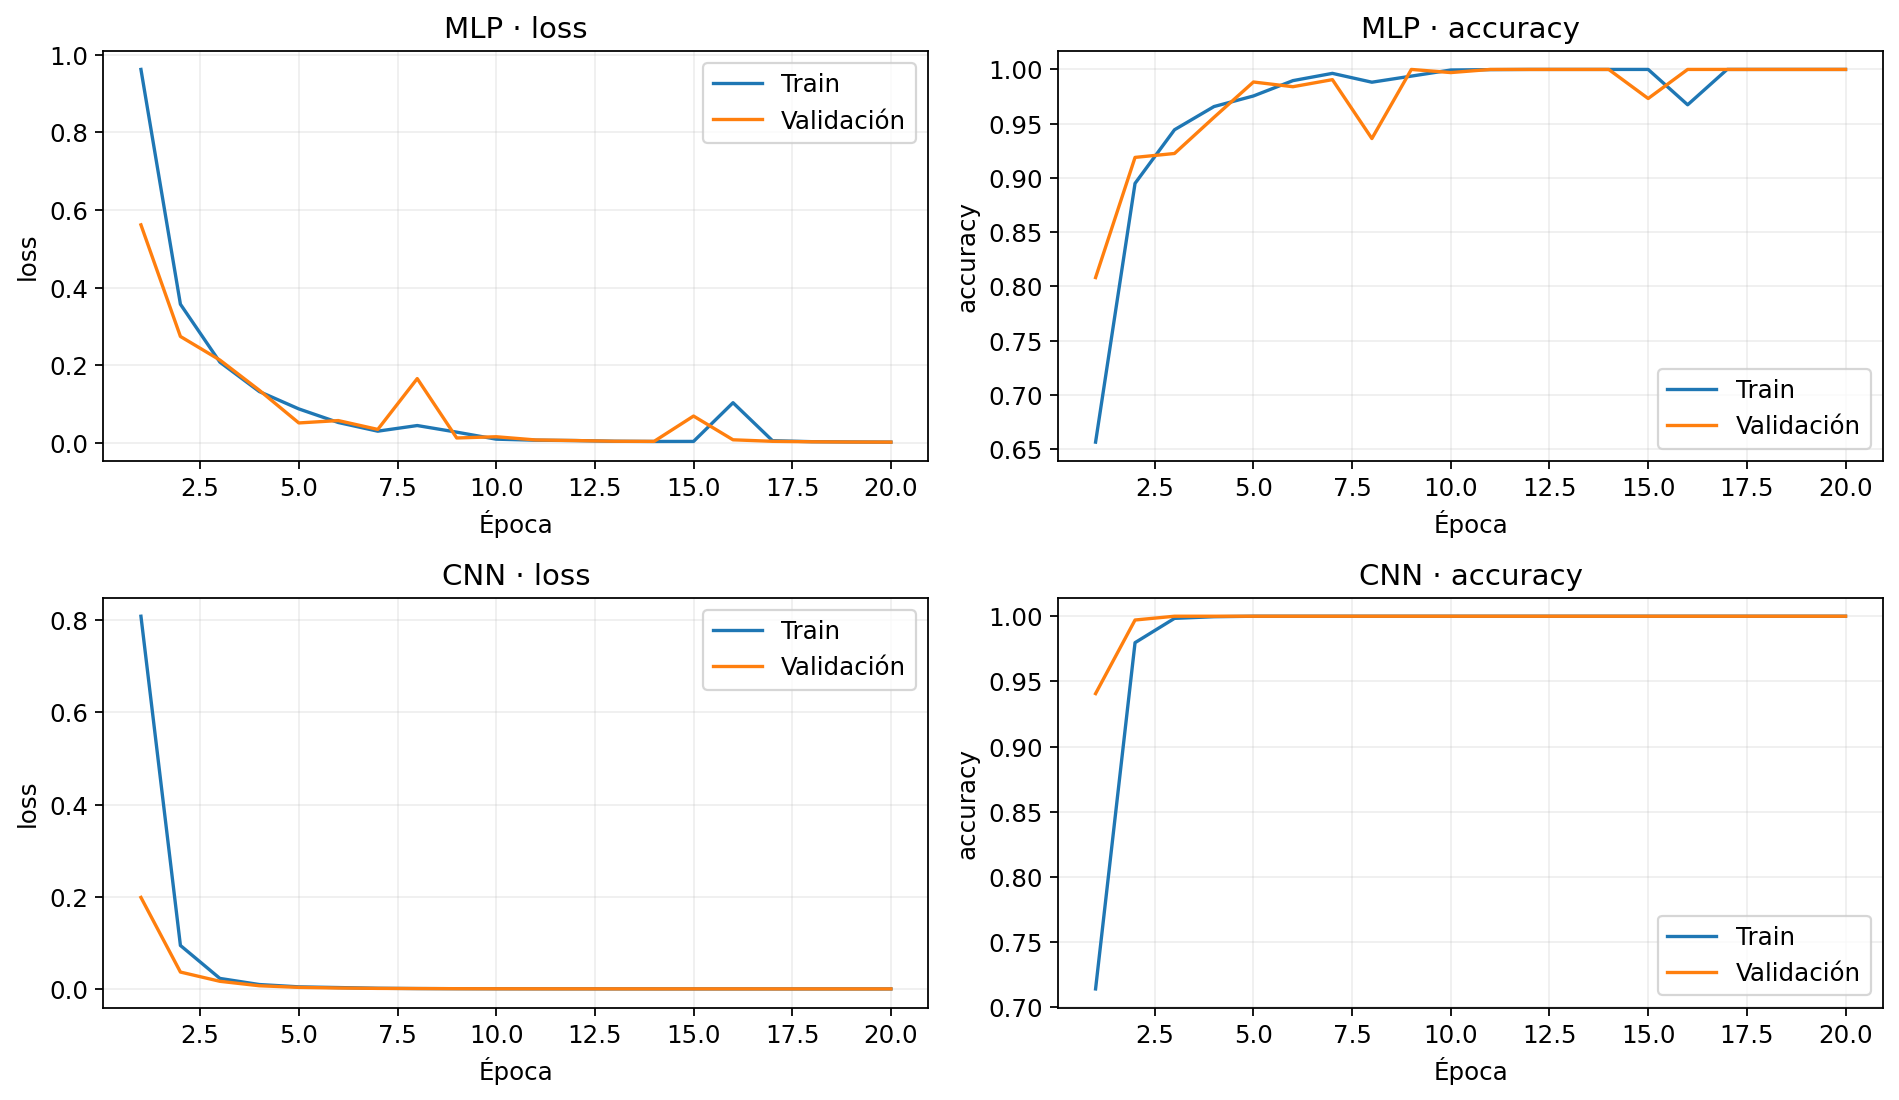

In [4]:
fig,axs=plt.subplots(2,2,figsize=(12,7))
for row,name in enumerate(['MLP','CNN']):
    h=histories[name]
    for col,key in enumerate(['loss','accuracy']):
        axs[row,col].plot(range(1,EPOCHS+1),h[key],label='Train')
        axs[row,col].plot(range(1,EPOCHS+1),h['val_'+key],label='Validación')
        axs[row,col].set(title=f'{name} · {key}',xlabel='Época',ylabel=key);axs[row,col].legend();axs[row,col].grid(alpha=.2)
savefig('curvas.png')
for name,h in histories.items():
    print(name, 'Tiempo (s):',round(times[name],3),'época de menor val_loss:',1+int(np.argmin(h['val_loss'])), 'última val_loss:',h['val_loss'][-1])

## 5. Evaluación de ambos modelos
Se calcula accuracy, precision, recall y F1 macro y ponderados, reportes por clase, pérdida y matrices de confusión. Macro asigna igual peso a cada letra. El promedio ponderado considera su soporte. Las filas de las matrices son clases reales y las columnas predicciones.

La latencia usa 100 inferencias individuales después de 10 calentamientos. Se informa mediana y percentil 95. No incluye cámara ni preprocesamiento. Las probabilidades Softmax no se interpretan como confianza calibrada.

MLP
CNN


Unnamed: 0,precision,recall,f1-score,support
A,1.0000,1.0000,1.0000,331.0000
C,0.9063,0.9677,0.9360,310.0000
F,0.7930,0.9150,0.8496,247.0000
K,0.8318,0.8066,0.8190,331.0000
O,0.9950,0.8049,0.8899,246.0000
Y,0.7758,0.7711,0.7734,332.0000
accuracy,0.8781,0.8781,0.8781,0.8781
macro avg,0.8836,0.8776,0.8780,1797.0000
weighted avg,0.8823,0.8781,0.8780,1797.0000


Unnamed: 0,precision,recall,f1-score,support
A,1.0000,1.0000,1.0000,331.0000
C,1.0000,1.0000,1.0000,310.0000
F,0.9464,1.0000,0.9724,247.0000
K,0.9405,0.9547,0.9475,331.0000
O,1.0000,0.8618,0.9258,246.0000
Y,0.9568,1.0000,0.9779,332.0000
accuracy,0.9727,0.9727,0.9727,0.9727
macro avg,0.9739,0.9694,0.9706,1797.0000
weighted avg,0.9737,0.9727,0.9723,1797.0000


model,parameters,fit_seconds,errors,latency_median_ms,latency_p95_ms,train_loss,train_accuracy,val_loss,val_accuracy,test_loss,test_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,train_test_gap_pp,train_val_gap_pp
MLP,109126,23.8483,219,2.2328,3.9108,0.0013,1.0,0.0016,1.0,0.5407,0.8781,0.8836,0.8776,0.8780,0.8823,0.8781,0.8780,12.1870,0.0
CNN,56454,26.9969,49,4.7090,6.0583,0.0000,1.0,0.0001,1.0,0.0799,0.9727,0.9739,0.9694,0.9706,0.9737,0.9727,0.9723,2.7268,0.0


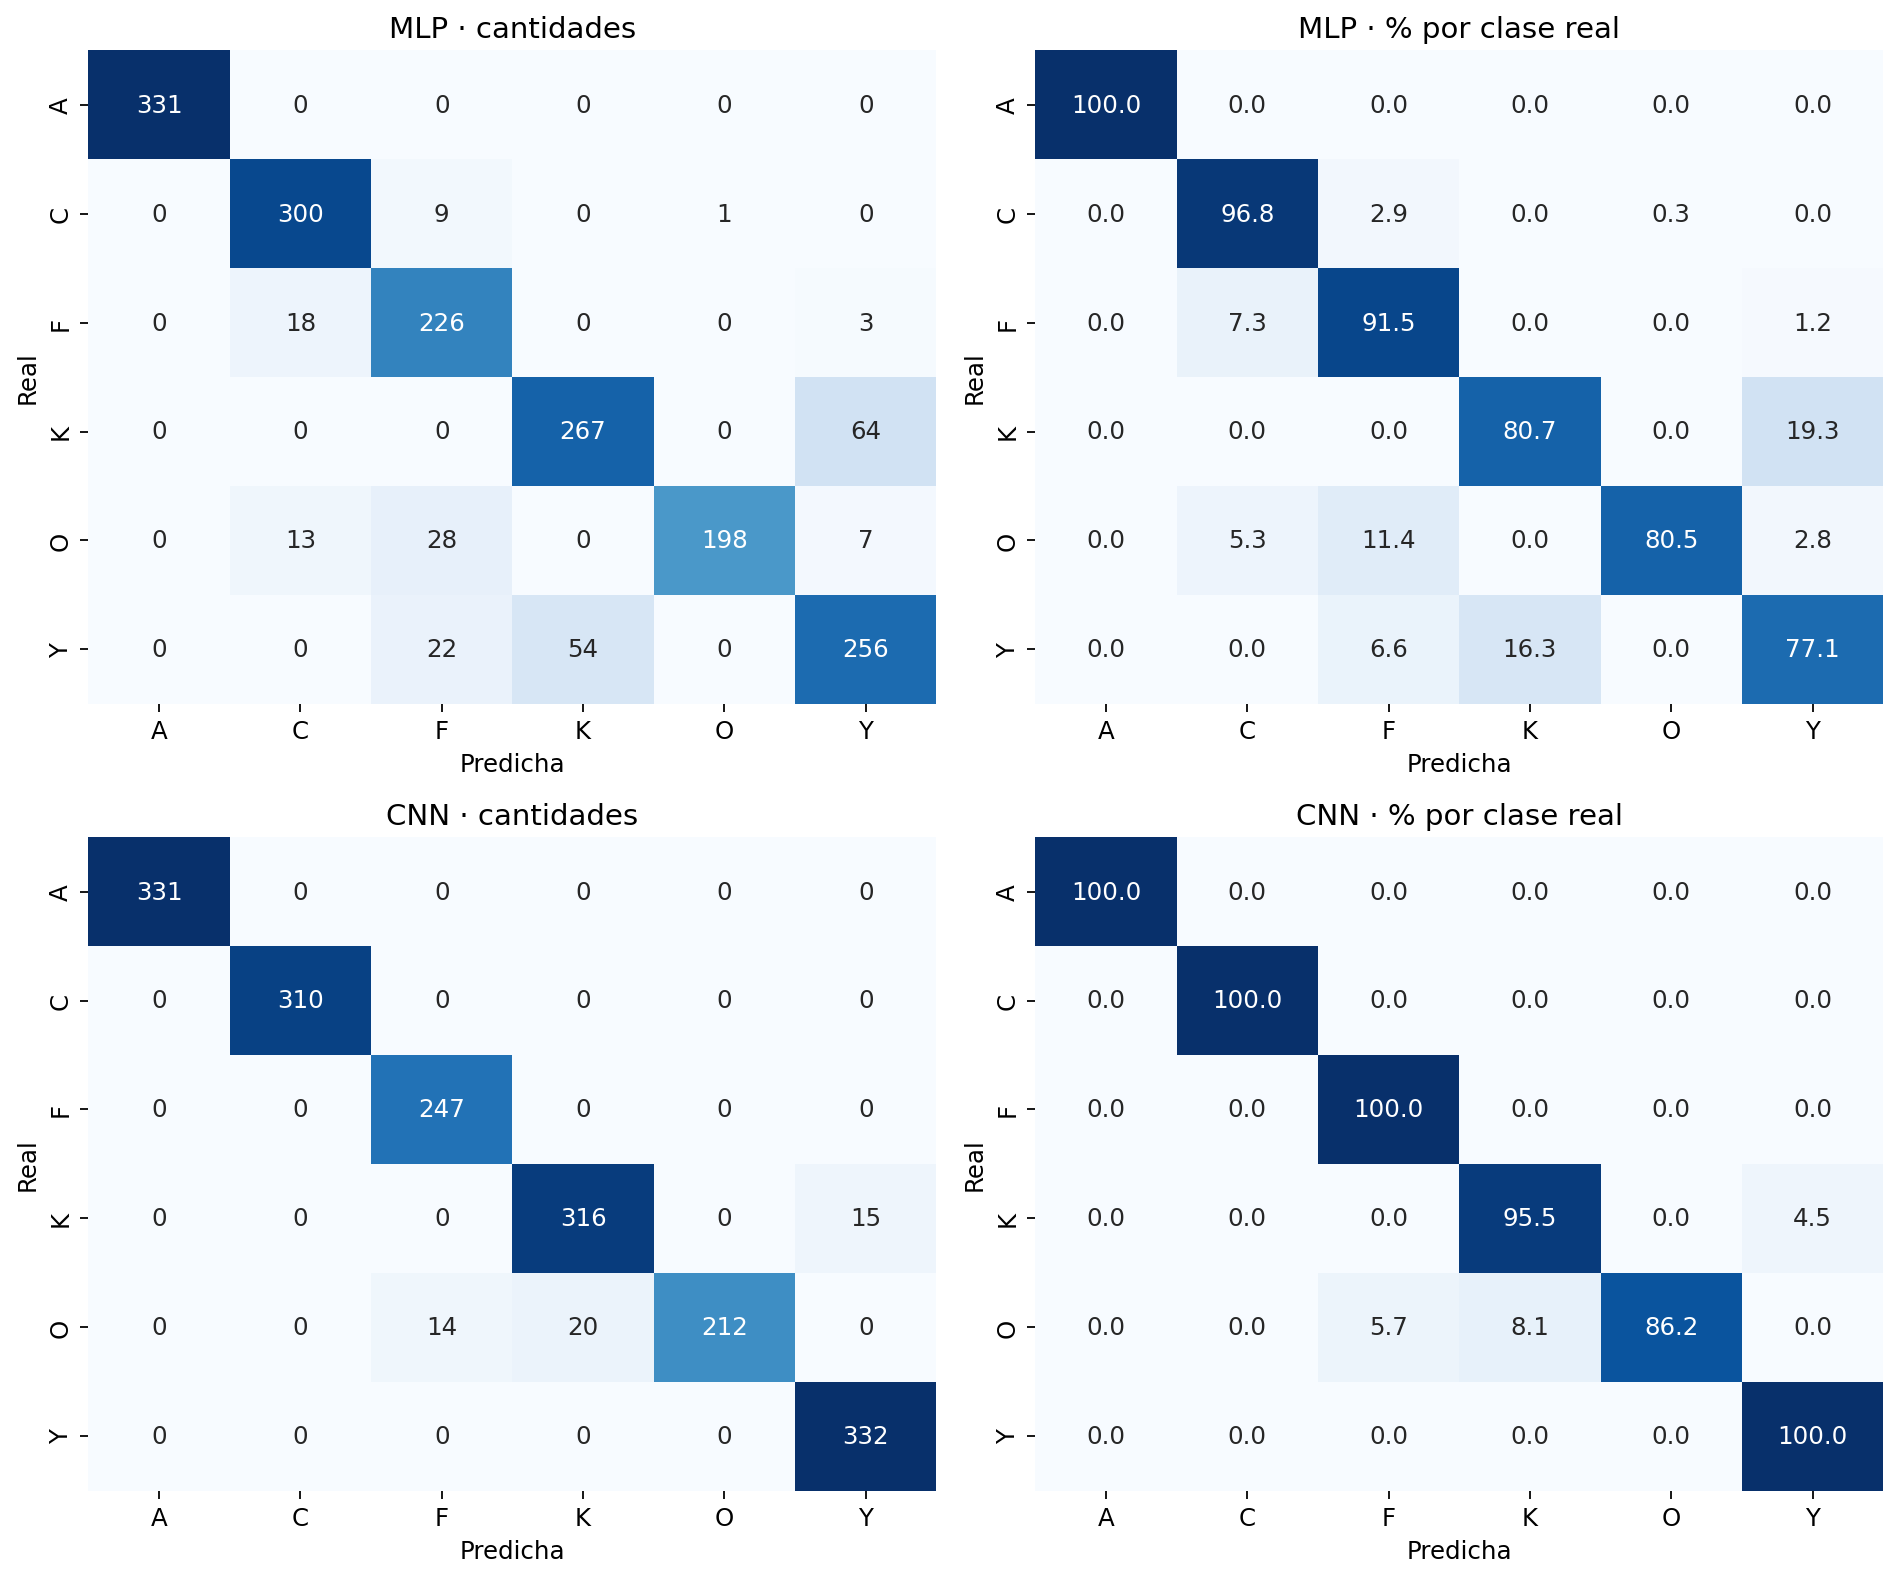

In [5]:
rows=[];probs={};preds={};reports={};cms={}
for name,tr,va,te in [('MLP',Xtr,Xva,Xt),('CNN',CTr,CVa,CTe)]:
    model=models[name]
    probs[name]=model.predict(dataset(te,yt),verbose=0)
    preds[name]=probs[name].argmax(1)
    reports[name]=classification_report(yt,preds[name],target_names=LETTERS,output_dict=True,zero_division=0)
    pd.DataFrame(reports[name]).T.to_csv(ROOT/'results'/f'report_{name.lower()}.csv')
    pd.DataFrame({'csv_row':test.index,'true':yt,'predicted':preds[name],'true_letter':np.array(LETTERS)[yt],'predicted_letter':np.array(LETTERS)[preds[name]],'probability':probs[name].max(1)}).to_csv(ROOT/'results'/f'predictions_{name.lower()}.csv',index=False)
    for _ in range(10):model(te[:1],training=False).numpy()
    latency=[]
    for _ in range(100):
        t=time.perf_counter();model(te[:1],training=False).numpy();latency.append((time.perf_counter()-t)*1000)
    evals={split:model.evaluate(dataset(x,z),verbose=0) for split,x,z in [('train',tr,ytr),('val',va,yva),('test',te,yt)]}
    row={'model':name,'parameters':model.count_params(),'fit_seconds':times[name],'errors':int((preds[name]!=yt).sum()),'latency_median_ms':float(np.median(latency)),'latency_p95_ms':float(np.percentile(latency,95))}
    for split,values in evals.items():row[split+'_loss'],row[split+'_accuracy']=values
    for avg in ['macro','weighted']:
        for label,fun in [('precision',precision_score),('recall',recall_score),('f1',f1_score)]: row[label+'_'+avg]=fun(yt,preds[name],average=avg,zero_division=0)
    row['train_test_gap_pp']=100*(row['train_accuracy']-row['test_accuracy'])
    row['train_val_gap_pp']=100*(row['train_accuracy']-row['val_accuracy'])
    rows.append(row)
    cms[name]=confusion_matrix(yt,preds[name],labels=range(6))
    pd.DataFrame(cms[name],index=LETTERS,columns=LETTERS).to_csv(ROOT/'results'/f'confusion_{name.lower()}.csv')
    print(name);display(pd.DataFrame(reports[name]).T.round(4))
metrics=pd.DataFrame(rows).set_index('model');metrics.to_csv(ROOT/'results/metrics.csv')
(ROOT/'results/metrics.json').write_text(metrics.to_json(orient='index',indent=2))
display(metrics.round(4))
fig,axs=plt.subplots(2,2,figsize=(12,10))
for i,name in enumerate(['MLP','CNN']):
    cm=cms[name]
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=LETTERS,yticklabels=LETTERS,ax=axs[i,0],cbar=False)
    sns.heatmap(cm/cm.sum(1,keepdims=True)*100,annot=True,fmt='.1f',cmap='Blues',vmin=0,vmax=100,xticklabels=LETTERS,yticklabels=LETTERS,ax=axs[i,1],cbar=False)
    for j in range(2):axs[i,j].set(xlabel='Predicha',ylabel='Real',title=f'{name} · '+('cantidades' if j==0 else '% por clase real'))
savefig('matrices.png')

## 6. Comparación experimental
La comparación principal usa los modelos reentrenados con el mismo orden de lotes mediante `tf.data`, datos y hardware. La evidencia histórica E1 permanece separada porque el entorno y la implementación del barajado pueden cambiar los resultados aun con semilla 42.

El notebook E1 registra **32,7547 s**, mientras la presentación dice **35,18 s**. Se conserva el dato del registro ejecutado y se documenta la discrepancia. Ninguno se usa para afirmar una mejora de velocidad contra la CNN actual.

Diferencia CNN − MLP actual: 9.46 puntos porcentuales.
CNN usa 48.27% menos parámetros.
MLP: brecha train-test 12.19 pp; accuracy≥90%: False; F1 macro≥0,88: False; error<5%: False; latencia p95<10 ms: True
CNN: brecha train-test 2.73 pp; accuracy≥90%: True; F1 macro≥0,88: True; error<5%: True; latencia p95<10 ms: True


modelo,accuracy,precision_macro,recall_macro,f1_macro,parameters,errors
MLP histórico E1,0.8703,0.8778,0.8698,0.8694,109126,233


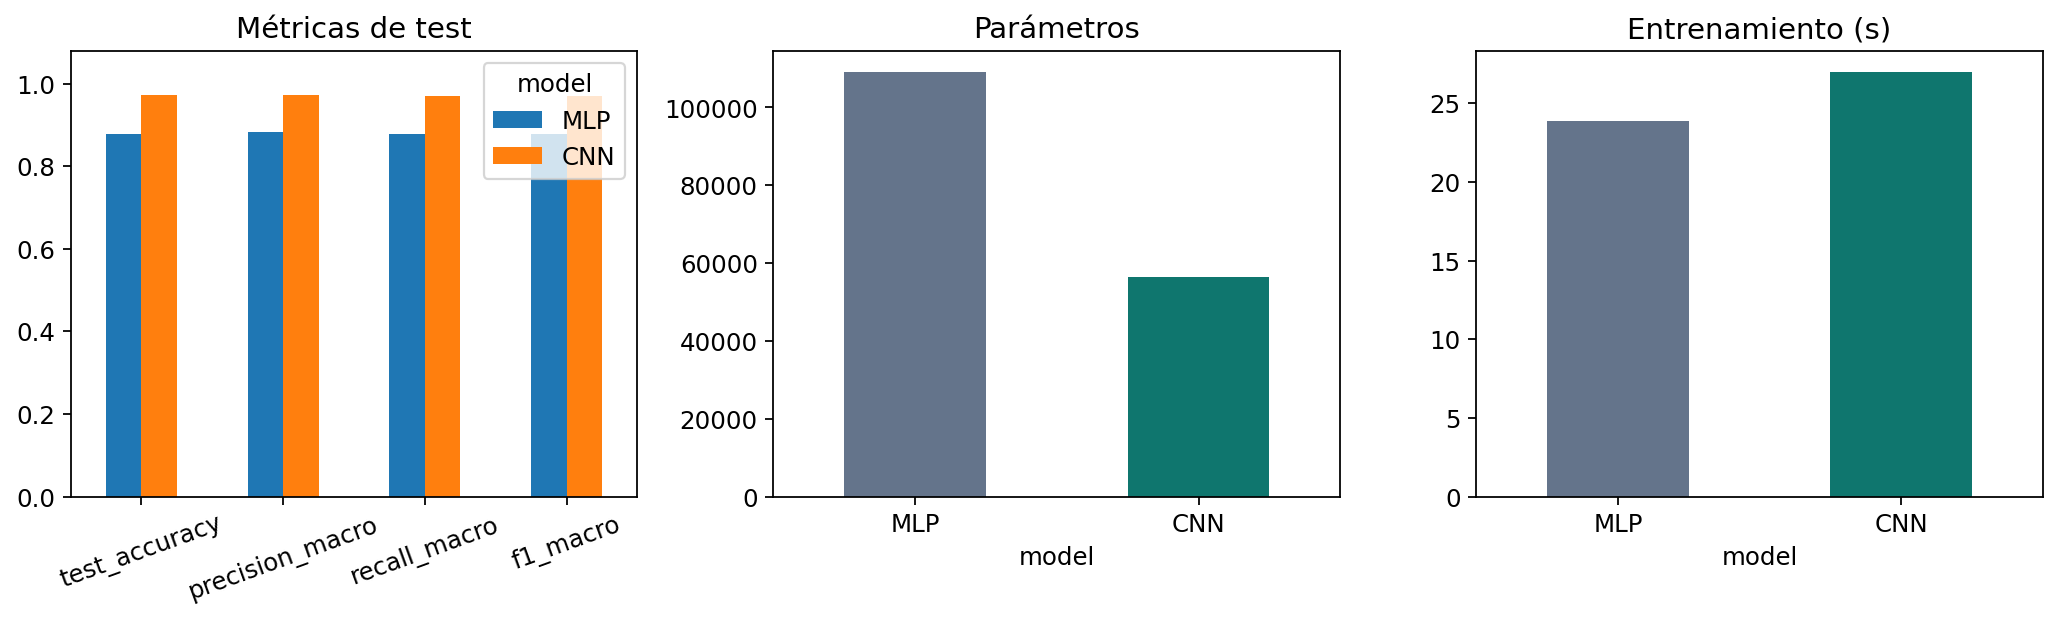

In [6]:
historical=pd.DataFrame([{'modelo':'MLP histórico E1','accuracy':.8703,'precision_macro':.8778,'recall_macro':.8698,'f1_macro':.8694,'parameters':109126,'errors':233}])
historical.to_csv(ROOT/'results/historical_e1.csv',index=False)
display(historical)
fig,axs=plt.subplots(1,3,figsize=(13,4))
metrics[['test_accuracy','precision_macro','recall_macro','f1_macro']].T.plot.bar(ax=axs[0],rot=20,ylim=(0,1.08));axs[0].set_title('Métricas de test')
metrics.parameters.plot.bar(ax=axs[1],rot=0,color=['#64748b','#0f766e']);axs[1].set_title('Parámetros')
metrics.fit_seconds.plot.bar(ax=axs[2],rot=0,color=['#64748b','#0f766e']);axs[2].set_title('Entrenamiento (s)')
savefig('comparacion.png')
delta=100*(metrics.loc['CNN','test_accuracy']-metrics.loc['MLP','test_accuracy'])
print(f'Diferencia CNN − MLP actual: {delta:.2f} puntos porcentuales.')
print(f'CNN usa {100*(1-56454/109126):.2f}% menos parámetros.')
for name in metrics.index:
    m=metrics.loc[name]
    print(f"{name}: brecha train-test {m.train_test_gap_pp:.2f} pp; accuracy≥90%: {m.test_accuracy>=.9}; F1 macro≥0,88: {m.f1_macro>=.88}; error<5%: {1-m.test_accuracy<.05}; latencia p95<10 ms: {m.latency_p95_ms<10}")

## 7. Aciertos, errores y limitaciones
Los ejemplos se eligen de forma determinista. Se muestran hasta seis aciertos y seis errores por modelo, con fila del CSV, etiqueta real, predicha y probabilidad. Si una ejecución no produce errores, se declara explícitamente y no se fabrican ejemplos. El CSV conserva todas las predicciones para auditoría.

MLP probabilidad media en aciertos: 0.97511536 en errores: 0.7548858
CNN probabilidad media en aciertos: 0.9960755 en errores: 0.831842


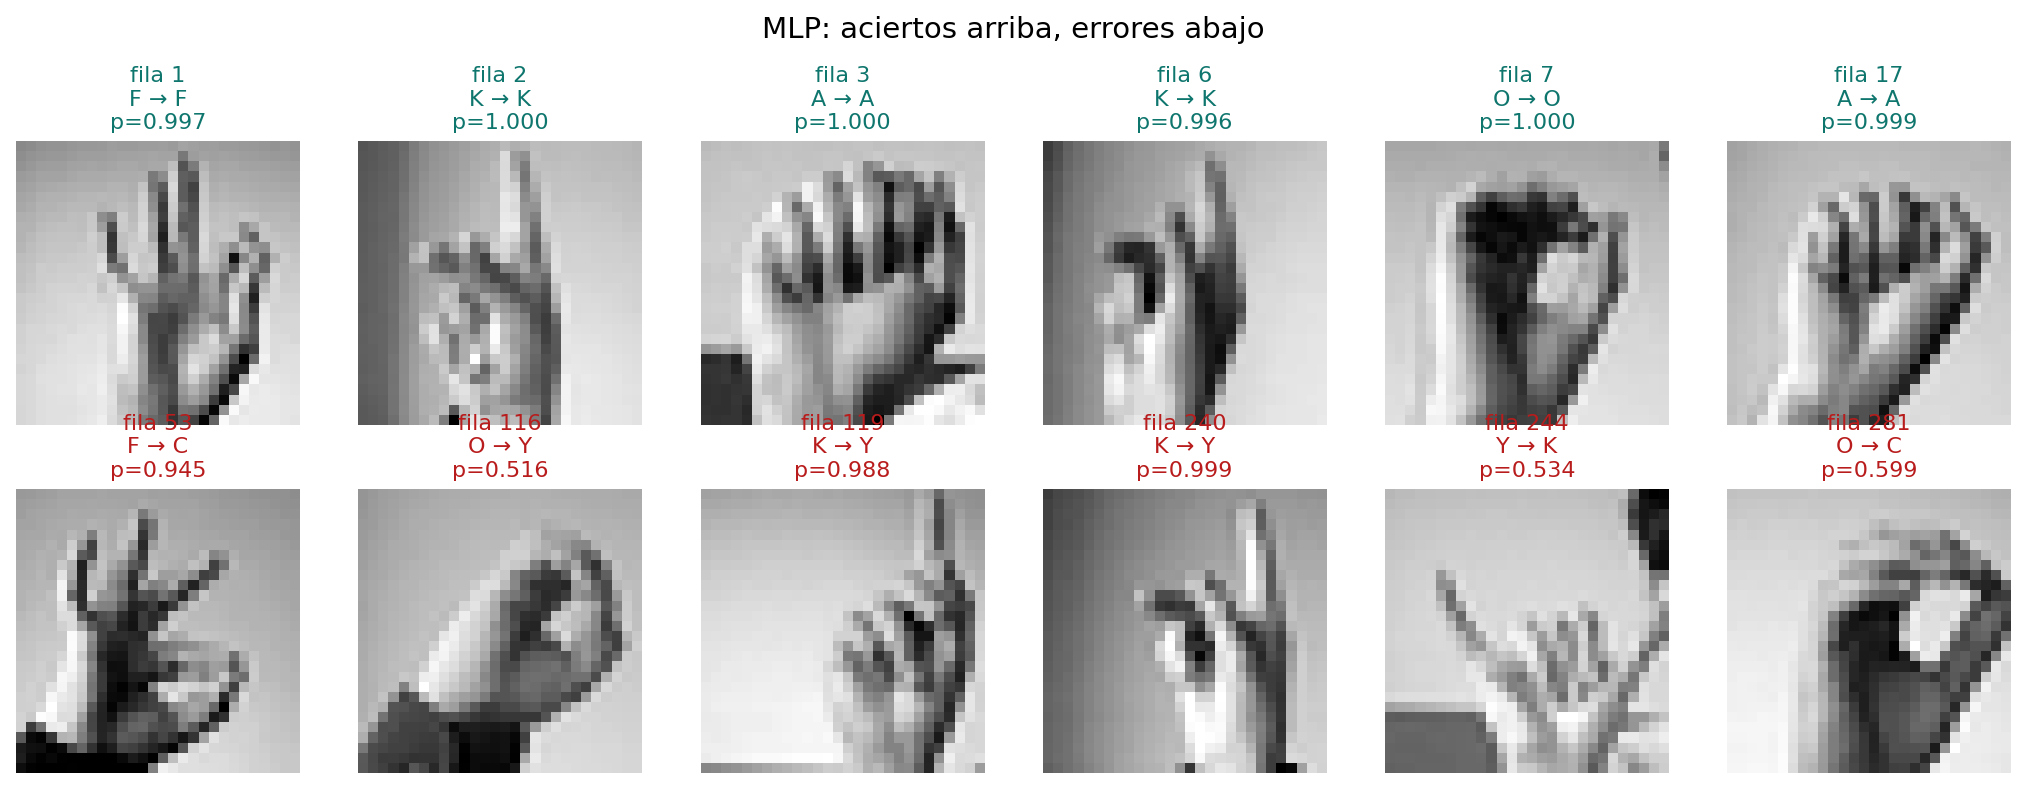

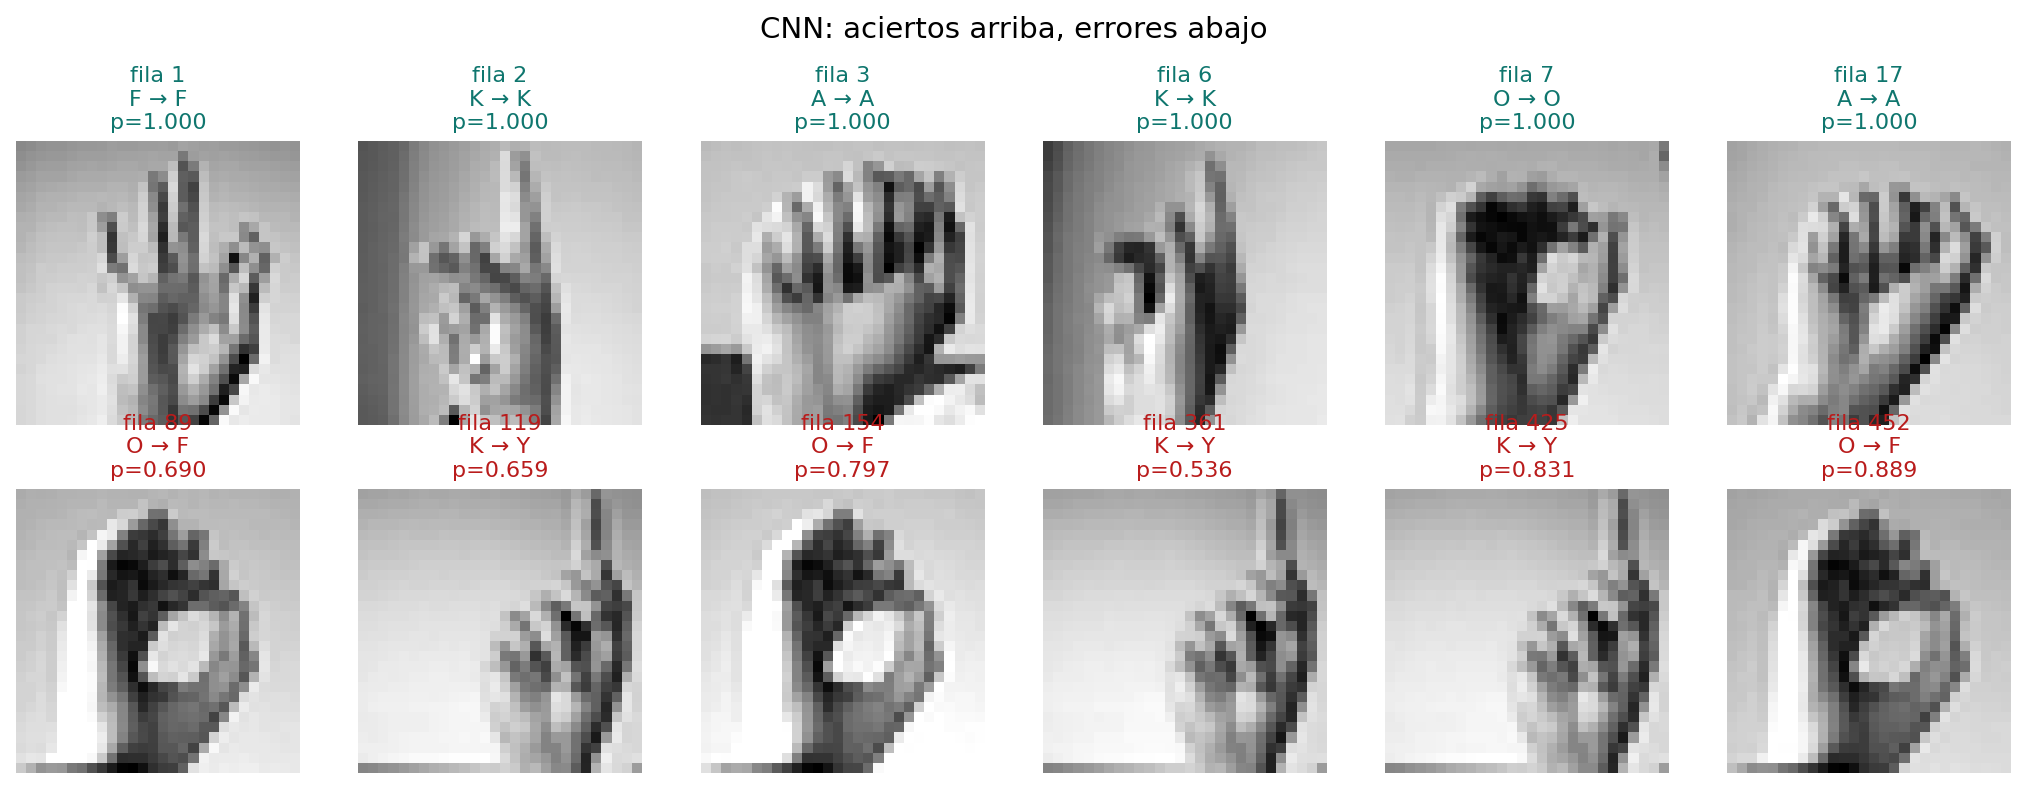

model,real,predicted,count,percent_of_class
MLP,K,Y,64,19.3353
MLP,Y,K,54,16.2651
MLP,O,F,28,11.3821
MLP,Y,F,22,6.6265
CNN,O,K,20,8.1301
MLP,F,C,18,7.2874
CNN,K,Y,15,4.5317
CNN,O,F,14,5.6911
MLP,O,C,13,5.2846
MLP,C,F,9,2.9032


In [7]:
confusions=[]
for name in ['MLP','CNN']:
    cm=cms[name]
    for i in range(6):
        for j in range(6):
            if i!=j and cm[i,j]>0:confusions.append({'model':name,'real':LETTERS[i],'predicted':LETTERS[j],'count':int(cm[i,j]),'percent_of_class':100*cm[i,j]/cm[i].sum()})
    fig,axs=plt.subplots(2,6,figsize=(13,5))
    for row,correct in enumerate([True,False]):
        ids=np.flatnonzero((preds[name]==yt)==correct)[:6]
        for j,ax in enumerate(axs[row]):
            ax.axis('off')
            if j<len(ids):
                ix=ids[j];ax.imshow(CTe[ix,:,:,0],cmap='gray');ax.set_title(f'fila {test.index[ix]}\n{LETTERS[yt[ix]]} → {LETTERS[preds[name][ix]]}\np={probs[name][ix].max():.3f}',fontsize=10,color='#0f766e' if correct else '#b91c1c')
            elif j==0:ax.text(.1,.5,'Sin errores' if not correct else 'Sin aciertos')
    plt.suptitle(f'{name}: aciertos arriba, errores abajo');savefig(f'ejemplos_{name.lower()}.png')
confusion_table=pd.DataFrame(confusions,columns=['model','real','predicted','count','percent_of_class']).sort_values('count',ascending=False)
confusion_table.to_csv(ROOT/'results/error_pairs.csv',index=False);display(confusion_table)
for name in ['MLP','CNN']:
    ok=preds[name]==yt
    print(name,'probabilidad media en aciertos:',probs[name][ok].max(1).mean(), 'en errores:',probs[name][~ok].max(1).mean() if (~ok).any() else 'no aplica')

## 8. Feature Maps en diferentes profundidades
Para cada letra se selecciona la primera imagen de test correctamente clasificada, o la primera disponible si no hay aciertos. Se muestran la entrada y los primeros cuatro canales de cada convolución, sin elegir los filtros más vistosos. Son respuestas después de ReLU. Cada mapa usa su escala individual: el brillo entre mapas no mide magnitudes comparables.

Conv1 conserva resolución 26×26 y campo receptivo 3×3. Conv2 tiene resolución 11×11 y campo receptivo 8×8 de la entrada (incluye el pooling previo). Por eso puede combinar patrones locales en regiones mayores. Los patrones visibles pueden ser compatibles con bordes o partes de dedos, pero cada filtro carece de un significado semántico garantizado.

Fracción de ceros por capa: 0.14158037475345167 0.20730027548209368


/root/.local/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_4']
Received: inputs=Tensor(shape=(6, 28, 28, 1))
  warnings.warn(msg)


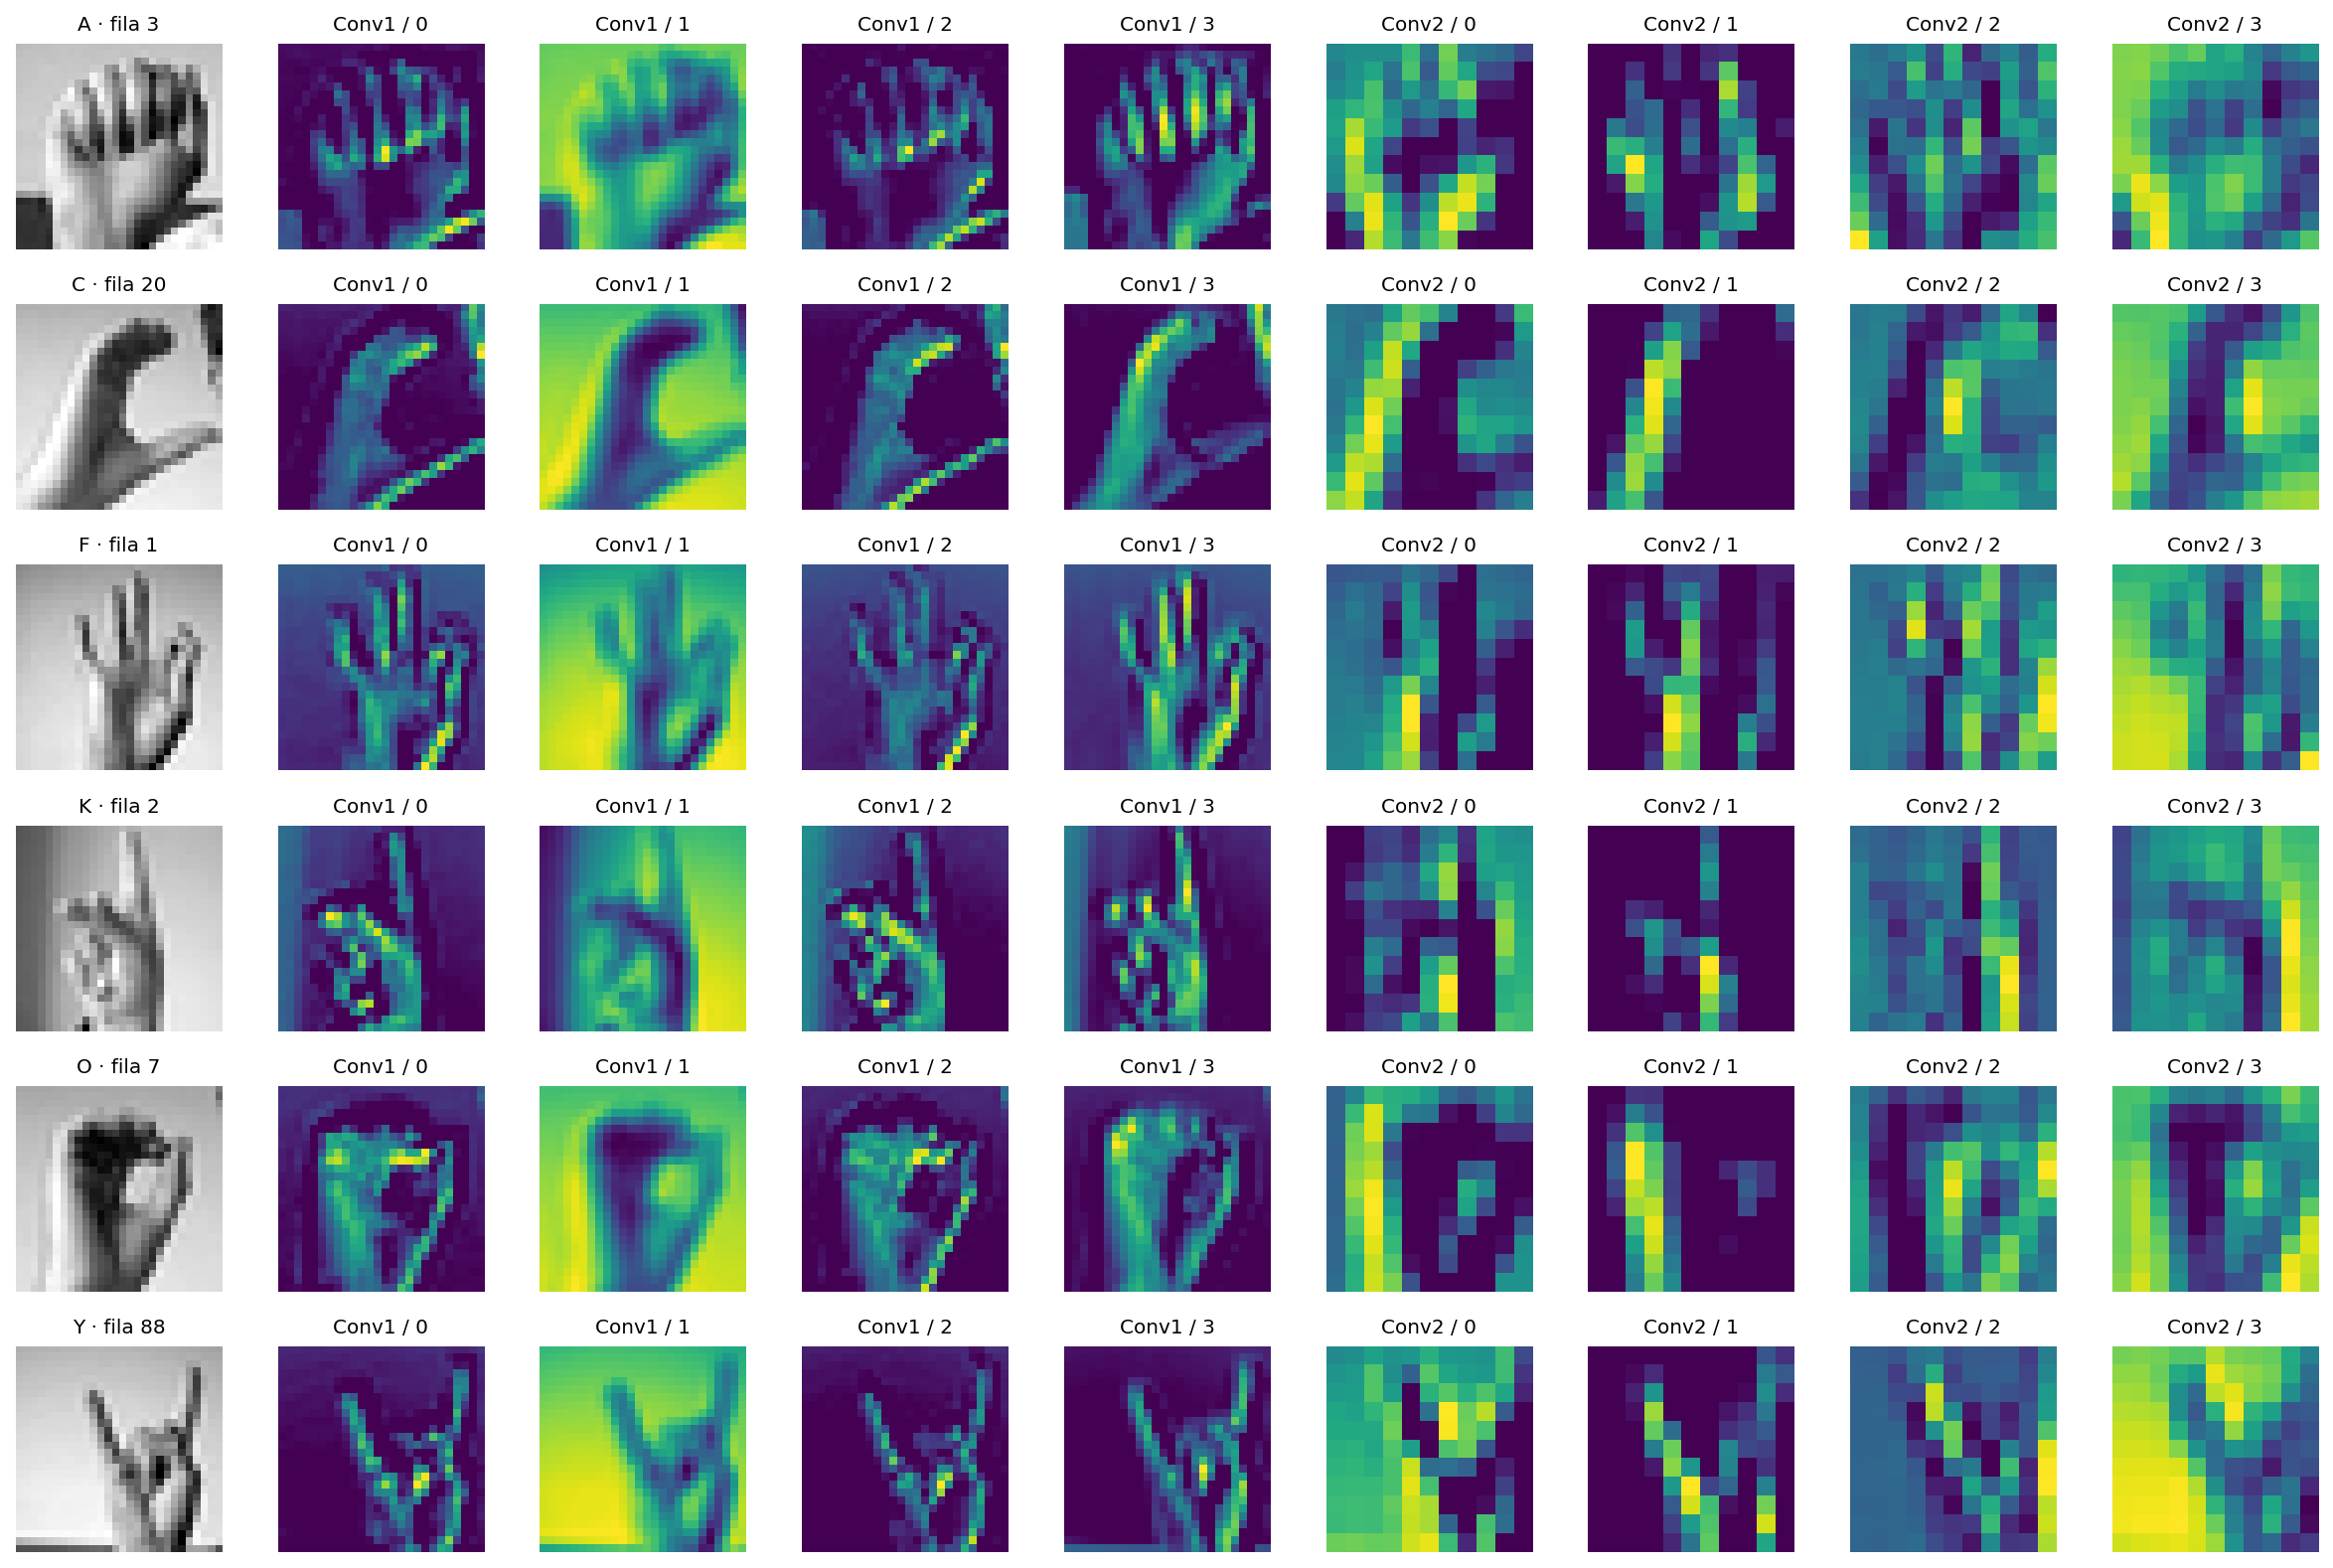

In [8]:
cnn=models['CNN']
feature_model=tf.keras.Model(cnn.inputs,[cnn.get_layer('conv1').output,cnn.get_layer('conv2').output])
representatives=[]
for k in range(6):
    ids=np.flatnonzero((yt==k)&(preds['CNN']==k))
    representatives.append(int(ids[0] if len(ids) else np.flatnonzero(yt==k)[0]))
f1,f2=feature_model(CTe[representatives],training=False)
fig,axs=plt.subplots(6,9,figsize=(15,10))
for r,ix in enumerate(representatives):
    axs[r,0].imshow(CTe[ix,:,:,0],cmap='gray');axs[r,0].set_title(f'{LETTERS[r]} · fila {test.index[ix]}',fontsize=9)
    for k in range(4):
        axs[r,k+1].imshow(f1[r,:,:,k],cmap='viridis');axs[r,k+1].set_title(f'Conv1 / {k}',fontsize=9)
        axs[r,k+5].imshow(f2[r,:,:,k],cmap='viridis');axs[r,k+5].set_title(f'Conv2 / {k}',fontsize=9)
for ax in axs.flat:ax.axis('off')
savefig('feature_maps.png')
np.savez_compressed(ROOT/'results/feature_maps.npz',conv1=f1.numpy(),conv2=f2.numpy(),test_filtered_indices=representatives)
print('Fracción de ceros por capa:',float(np.mean(f1.numpy()==0)),float(np.mean(f2.numpy()==0)))

## 9. Mapa de activación específico de cada clase: Grad-CAM
Feature Maps describen filtros y no son por sí solos mapas de una clase. Para cumplir el requisito adicional se calcula **Grad-CAM para cada una de las seis clases**, sobre su imagen representativa. Se deriva el logit de la clase respecto a los mapas de Conv2, se promedian espacialmente los gradientes, se ponderan los canales y se aplica ReLU. El logit evita la saturación de Softmax. La normalización por imagen permite visualizar importancia relativa, no comparar intensidad absoluta entre clases.

Se superpone la respuesta de 11×11, interpolada a 28×28 solo para visualización. El modelo conserva su entrada original. Es una explicación aproximada, de resolución gruesa, sin probar causalidad ni que la red comprende la anatomía de la mano. Un mapa nulo se informa como tal.

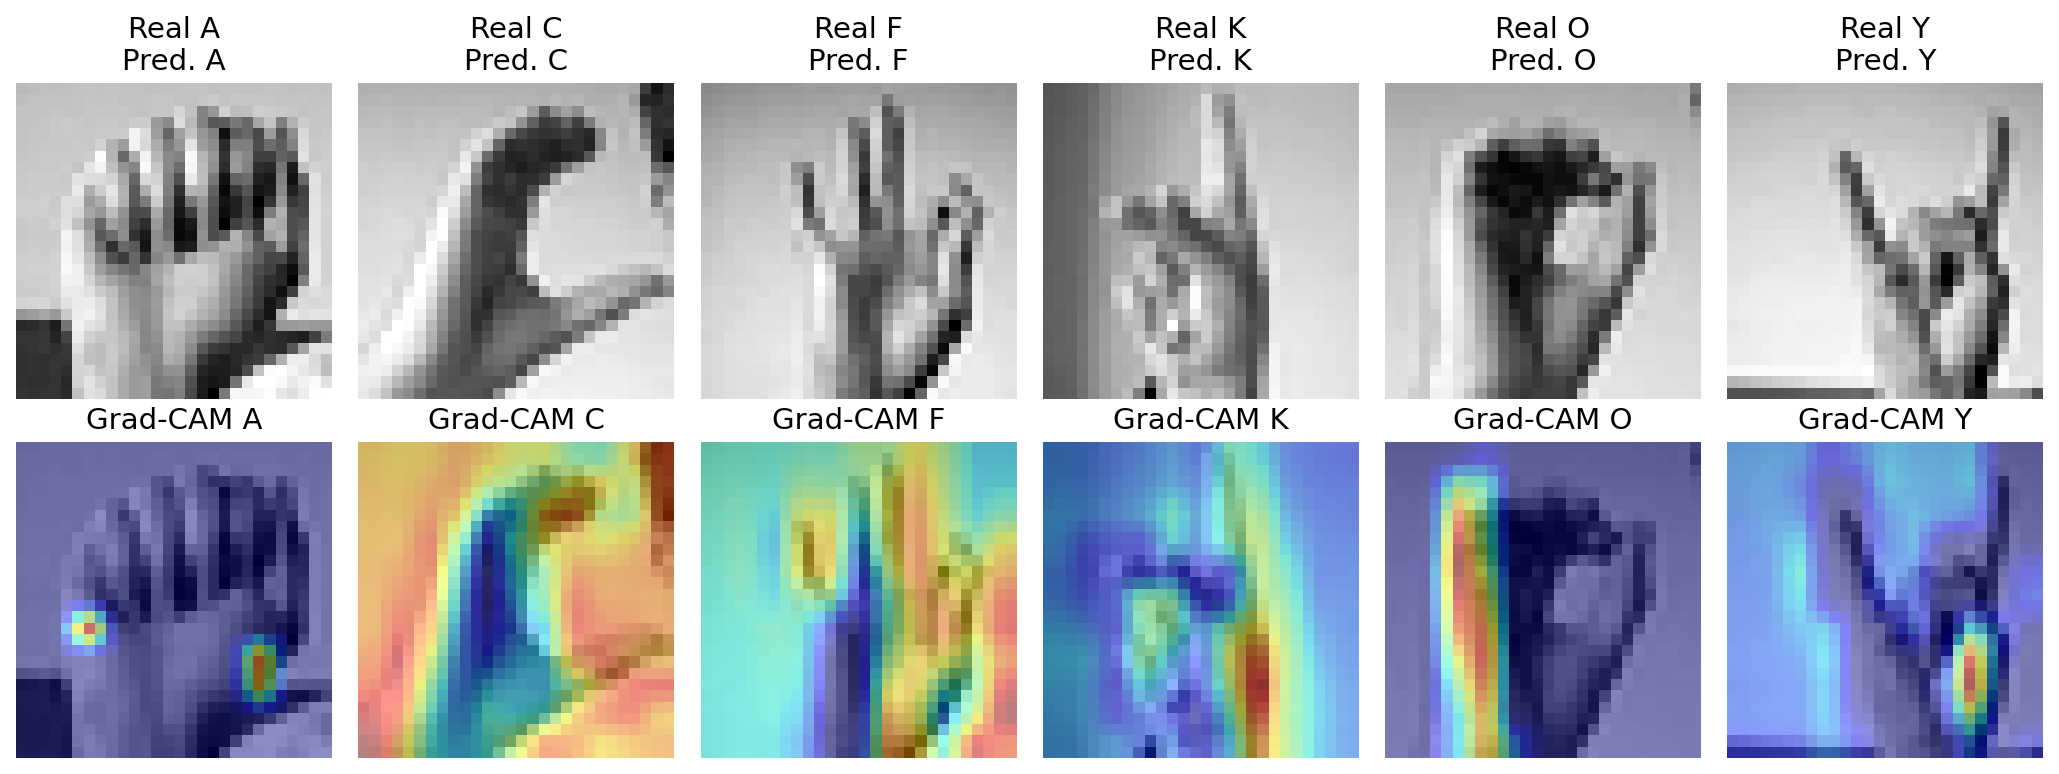

In [9]:
grad_model=tf.keras.Model(cnn.inputs,[cnn.get_layer('conv2').output,cnn.get_layer('salida').input])
last=cnn.get_layer('salida')
heats=[]
fig,axs=plt.subplots(2,6,figsize=(13,5))
for k,ix in enumerate(representatives):
    image=tf.convert_to_tensor(CTe[ix:ix+1])
    with tf.GradientTape() as tape:
        conv,features=grad_model(image,training=False)
        logits=tf.matmul(features,last.kernel)+last.bias
        score=logits[:,k]
    gradients=tape.gradient(score,conv)
    assert gradients is not None
    weights=tf.reduce_mean(gradients,axis=(0,1,2))
    heat=tf.nn.relu(tf.reduce_sum(conv[0]*weights,axis=-1))
    maximum=float(tf.reduce_max(heat))
    heat=heat/(maximum+1e-10)
    heat=tf.image.resize(heat[...,None],(28,28)).numpy()[:,:,0]
    heats.append(heat)
    axs[0,k].imshow(CTe[ix,:,:,0],cmap='gray');axs[0,k].set_title(f'Real {LETTERS[k]}\nPred. {LETTERS[preds["CNN"][ix]]}')
    axs[1,k].imshow(CTe[ix,:,:,0],cmap='gray');axs[1,k].imshow(heat,cmap='jet',alpha=.45,vmin=0,vmax=1);axs[1,k].set_title(f'Grad-CAM {LETTERS[k]}' + (' (nulo)' if maximum==0 else ''))
for ax in axs.flat:ax.axis('off')
savefig('gradcam_clases.png')
np.savez_compressed(ROOT/'results/gradcam.npz',maps=np.array(heats),test_filtered_indices=representatives)
pd.DataFrame({'letter':LETTERS,'test_filtered_index':representatives,'csv_row':test.index.to_numpy()[representatives]}).to_csv(ROOT/'results/activation_examples.csv',index=False)

## 10. Conclusiones y reproducibilidad
La siguiente síntesis se calcula con los resultados reales de esta ejecución. No extrapola a otras personas, cámaras o lenguas de señas. La validación aleatoria procede del train oficial y puede ser más parecida al entrenamiento que el test. Se requiere evaluación por sujeto y con imágenes externas antes de un despliegue.

Las mejoras futuras incluyen más semillas, evaluación externa y ampliación a las 24 clases estáticas. No se añaden capas de regularización a esta entrega. J y Z requieren movimiento y quedan fuera del dataset de imágenes estáticas.

In [10]:
a,b=metrics.loc['MLP'],metrics.loc['CNN']
summary=f"""### Síntesis experimental
- MLP reentrenado: **{a.test_accuracy:.2%}** de accuracy, **{a.f1_macro:.4f}** F1 macro y **{int(a.errors)}** errores.
- CNN: **{b.test_accuracy:.2%}** de accuracy, **{b.f1_macro:.4f}** F1 macro y **{int(b.errors)}** errores.
- Diferencia de accuracy: **{100*(b.test_accuracy-a.test_accuracy):+.2f} puntos porcentuales**.
- Parámetros: **109.126 vs 56.454**. El costo convolucional depende también de operaciones y hardware, no solo de pesos.
- Tiempos de fit: **{a.fit_seconds:.2f} s vs {b.fit_seconds:.2f} s**, misma CPU y protocolo.
- Brecha train-test: **{a.train_test_gap_pp:.2f} pp vs {b.train_test_gap_pp:.2f} pp**.
- Evidencia histórica E1: 87,03% y F1 macro 0,8694. Debe distinguirse del MLP reentrenado.
"""
display(Markdown(summary));(ROOT/'results/summary.md').write_text(summary)
# Verificación de serialización y salida tras volver a cargar los modelos.
for name,x in [('MLP',Xt),('CNN',CTe)]:
    restored=tf.keras.models.load_model(ROOT/'models'/f'{name.lower()}.keras')
    np.testing.assert_allclose(restored(x[:8],training=False).numpy(),probs[name][:8],atol=1e-5)
print('Verificación correcta: modelos guardados, salidas equivalentes y seis probabilidades por imagen.')

Verificación correcta: modelos guardados, salidas equivalentes y seis probabilidades por imagen.


### Síntesis experimental
- MLP reentrenado: **87.81%** de accuracy, **0.8780** F1 macro y **219** errores.
- CNN: **97.27%** de accuracy, **0.9706** F1 macro y **49** errores.
- Diferencia de accuracy: **+9.46 puntos porcentuales**.
- Parámetros: **109.126 vs 56.454**. El costo convolucional depende también de operaciones y hardware, no solo de pesos.
- Tiempos de fit: **23.85 s vs 27.00 s**, misma CPU y protocolo.
- Brecha train-test: **12.19 pp vs 2.73 pp**.
- Evidencia histórica E1: 87,03% y F1 macro 0,8694. Debe distinguirse del MLP reentrenado.


### Lectura concreta de los resultados y figuras
En la CNN, A y C presentan precision y recall 1,0000. F e Y tienen recall 1,0000, pero reciben falsos positivos de O y K respectivamente. O es la clase más difícil: 212 aciertos de 246, recall 0,8618, aunque su precision es 1,0000 porque ninguna otra clase se predice como O. K presenta 316 aciertos de 331 y recall 0,9547.

Las tres confusiones CNN son **O→K (20)**, **K→Y (15)** y **O→F (14)**. Suman los 49 errores. El MLP reentrenado concentra 118 errores en K↔Y (64 K→Y y 54 Y→K). La CNN reduce esa confusión a 15, pero todavía falla en O. A 28×28, orientación, sombras y posición relativa de los dedos pueden inducir confusión. Esta es una hipótesis visual, no una causa demostrada mediante intervención.

Entre los ejemplos correctos CNN están F (fila 1), K (fila 2), A (fila 3) y O (fila 7). Entre los incorrectos, O→F en fila 89 tiene probabilidad 0,690, K→Y en fila 119 tiene 0,659 y O→F en fila 452 tiene 0,889. Una salida muy segura también puede estar equivocada. Las filas se refieren al CSV de test original, base cero y sin cabecera.

En Conv1, los canales 0, 2 y 3 resaltan diferentes contornos y cambios locales de intensidad alrededor de mano y dedos. El canal 1 muestra una respuesta más extendida. En Conv2, los mapas se vuelven más gruesos y selectivos: el canal 1 presenta zonas localizadas, y otros combinan áreas extensas. Esto concuerda con campos receptivos mayores, sin asignar a cada filtro un concepto fijo.

Grad-CAM varía según clase: A e Y muestran focos cerca de bordes inferiores o laterales de la mano; O destaca una banda a la izquierda de la mano; K concentra mayor activación hacia la zona inferior derecha. C y F presentan respuestas más extendidas, incluyendo fondo. Por tanto, **no se concluye que toda la atención se concentre en los dedos**. La respuesta al fondo es una limitación a investigar con imágenes externas. Estos mapas se normalizan por separado y ofrecen evidencia aproximada, no una explicación causal ni una segmentación.


## 11. Responsabilidades y defensa

| Actividad | Responsable propuesto | Revisor |
|---|---|---|
| Caso, continuidad E1, filtrado, calidad y particiones | Nicolás Fernández Vera | Bastian Gutierrez |
| Arquitectura, hiperparámetros y entrenamiento | Bastian Gutierrez | Victor Gutierrez |
| Métricas, errores y activaciones | Victor Gutierrez | Nicolás Fernández Vera |
| Informe, repositorio y reproducibilidad | Nicolás Fernández Vera | Ambos compañeros |
| Presentación y preparación de preguntas cruzadas | Los tres integrantes | Revisión conjunta |

Consultar el informe `README.md` y `docs/GUIA_DEFENSA.md`. Cada integrante debe poder explicar todas las etapas, no solo su segmento.